# Custom and library algorithms

Use five images from the published `benthic2` dataset, collected by JNCC from the 2013 East of Haig Fras survey to learn two ways to extend a pipeline.

| Step | Why we apply it |
| --- | --- |
| Open the five JPEGs | Keeping the exercise small makes it quick to repeat. The iFDO file pairs each JPEG with a timestamp, coordinates, and its source URL. |
| Grayscale | Convert to one intensity channel so it is easy to see what the two filters do and so the inversion and median filter operate on brightness alone. |
| Custom intensity inversion | Run code from the workshop’s `custom_algorithm/invert.py` to make an obvious visual change. This is a demonstration for learning how to connect your own code. |
| OpenCV median filter | Replace each intensity with the median of a 5 × 5 neighbourhood. Compare the result with the inverted image to see how the filter changes fine texture. |

The source metadata credits JNCC and Cefas and records the Open Government Licence v3.0. See the [source collection](https://jncc.resourcespace.com/pages/search.php?search=%21collection99) and [survey report](https://data.jncc.gov.uk/data/a74dc2aa-e8e9-4f23-81a2-287eefa7a47d/JNCC-CEFAS-28-FINAL-WEB.pdf).

## Configuration file

This is the configuration file used in this jupyter notebook


```yaml
general:
  input_path: "images/benthic2"
  metadata_path: "metadata/metadata_benthic2.json"
  metadata_type: "IFDO"
  output_path: output/extensions
  n_jobs: 1
  sampling:
    - mode: fixed
      params:
        value: 5

steps:
  - colour:
      name: grayscale
      mode: grayscale
  - custom:
      name: invert
      file_path: custom_algorithm/invert.py
      class_name: InvertColour
      processing_type: image
  - library:
      name: median_filter
      library: opencv
      function: medianBlur
      params:
        ksize: 5
```

## Run the code

### First, you need to correct the path (this is only necessary to make this notebook generic)

In [11]:
from os import chdir
from pathlib import Path

tutorial_dir = Path.home() / "paidiver" / "tutorials"
chdir(tutorial_dir)

### Import and instantiate pipeline class

In [4]:
from paidiverpy.pipeline import Pipeline

config_file_path = "config/config_extensions.yml"
pipeline = Pipeline(config_file_path=config_file_path, raise_error=True)
pipeline

☁ paidiverpy ☁  |    WARNING | 2026-11-27 17:04:24 | Failed to validate the IFDO metadata.
You can continue, but some functions may not work properly.
Please set verbose to 3 (DEBUG) to see the validation errors.
☁ paidiverpy ☁  |    WARNING | 2026-11-27 17:04:24 | Metadata does not have a camera-position type column. It should have one of the following columns: ['camera-position', 'camera_position', 'altitude_m', 'altitude_metre', 'altitude_meters', 'altitude_meter', 'image-altitude-meters']. 

☁ paidiverpy ☁  |    WARNING | 2026-11-27 17:04:24 | Metadata does not have a depth type column. It should have one of the following columns: ['depth', 'depth_m', 'depth_metres', 'depth_metre', 'depth_meters', 'depth_meter', 'image-depth']. 

☁ paidiverpy ☁  |    WARNING | 2026-11-27 17:04:24 | Metadata does not have a pitch type column. It should have one of the following columns: ['pitch', 'Pitch', 'Pitch_deg', 'pitch_deg', 'image-camera-pitch-degrees']. 

☁ paidiverpy ☁  |    WARNING | 2026-

### Inspect the custom and library steps

In the YAML, `class_name: InvertColour` selects the class in `custom_algorithm/invert.py` and `name: invert` selects its method. That method subtracts each pixel value from the largest value its integer type can hold. In an 8-bit image, 0 becomes 255 and 255 becomes 0.

More information on custom steps here: https://paidiverpy.readthedocs.io/en/latest/guide/custom_algorithms/index.html

And the library class calls a custom function from `open-cv` or `scikit-image`. More information here: https://paidiverpy.readthedocs.io/en/latest/guide/library_functions/index.html

## Run the pipeline and preview the images

The YAML also selects OpenCV’s `medianBlur` as the Library Layer function. Paidiverpy passes in the current image, along with the configured `ksize: 5`. That setting uses a 5 × 5 pixel neighbourhood. Try changing it to 3 in a copy of the YAML to compare the effect.

Run the next cell, then expand the image gallery to look at the same input across stages.

☁ paidiverpy ☁  |       INFO | 2026-11-27 17:04:56 | Processing images using 1 cores
☁ paidiverpy ☁  |       INFO | 2026-11-27 17:04:56 | Running step 0: raw - OpenLayer
☁ paidiverpy ☁  |       INFO | 2026-11-27 17:04:57 | Step 0 completed
☁ paidiverpy ☁  |       INFO | 2026-11-27 17:04:57 | Running step 1: grayscale - ColourLayer
☁ paidiverpy ☁  |       INFO | 2026-11-27 17:04:57 | Step 1 completed
☁ paidiverpy ☁  |       INFO | 2026-11-27 17:04:57 | Running step 2: invert - CustomLayer
☁ paidiverpy ☁  |       INFO | 2026-11-27 17:04:57 | Step 2 completed
☁ paidiverpy ☁  |       INFO | 2026-11-27 17:04:57 | Running step 3: median_filter - LibraryLayer
☁ paidiverpy ☁  |       INFO | 2026-11-27 17:04:57 | Step 3 completed



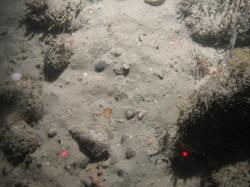
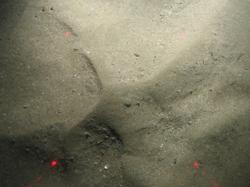
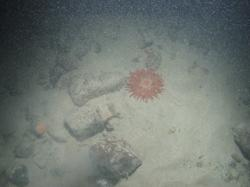
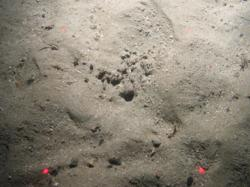
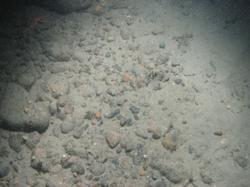
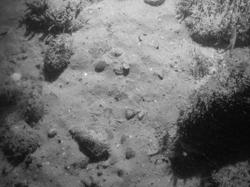
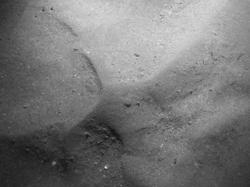
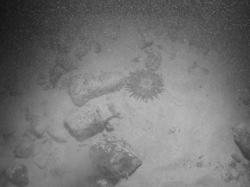
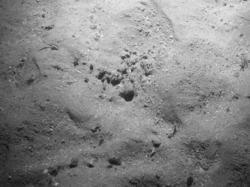
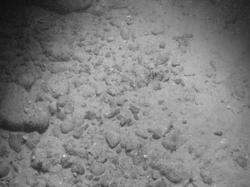
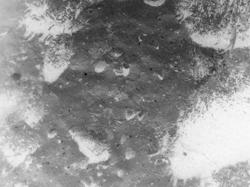
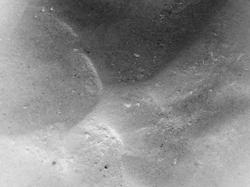
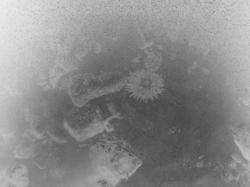
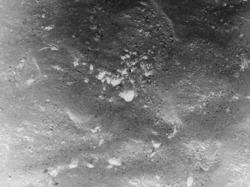
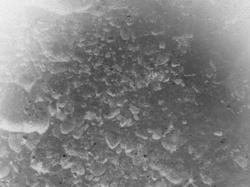
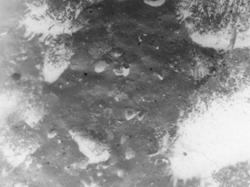
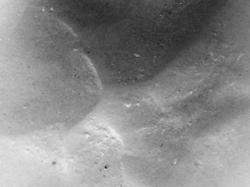
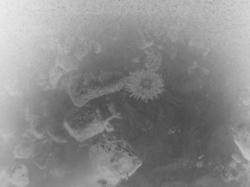
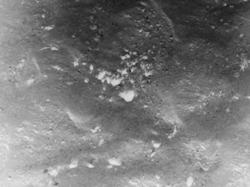
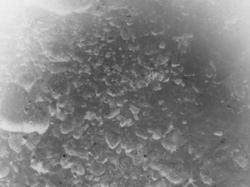

In [6]:
pipeline.run()
pipeline.images

# Now it's your turn!

Using the same dataset, explore the following tasks:

Copy `config/config_extension.yml` and edit the copy. Point `config_file_path` at it and rerun from the pipeline creation cell.

1. **Adjust hyperparameters** – Modify the hyperparameters of each step and observe their impact.  

3. **Add some specific steps using scikit-image or opencv**: More details [here](https://paidiverpy.readthedocs.io/en/latest/guide/library_functions/index.html)

4. **🔹 Advanced: Create a custom algorithm**  
   Develop your own processing step to extend the pipeline’s functionality. Learn how to do this in the [custom algorithms guide](https://paidiverpy.readthedocs.io/en/latest/guide/custom_algorithms/index.html).

In [7]:
#import the package
from paidiverpy.pipeline import Pipeline

In [8]:
# inspect the pipeline

In [9]:
# inspect the metadata

In [ ]:
# run the pipeline

In [ ]:
# see the output images

In [ ]:
# export the images